# 02 · Preprocessing and Information Extraction

**Use Case 3: Research Paper Analysis and Recommendation System**  
**Owner:** Member A (data & extraction lead)

**Goal:** Build the shared text-preprocessing pipeline and pull structured information (key phrases, methods, datasets, authors) out of the abstracts.

**Basic techniques (Weeks 1–6)**
- Text preprocessing: tokenisation, normalisation, lemmatisation, stop-word removal (spaCy / NLTK)
- POS tagging: key-phrase candidates from `ADJ* NOUN+` patterns
- NER + rule-based extraction: spaCy NER plus regex for method/dataset names (e.g. `BERT`, `ImageNet`), years and acronyms

**Advanced techniques (Weeks 7–12)**
- Few-shot LLM extraction (prompt with 3–5 worked examples), compared against the spaCy/regex output

**Evaluation:** Hand-label 20 test abstracts and report precision/recall/F1 for each extractor (rules vs NER vs LLM).

**Report section:** Introduction; dataset and preprocessing; basic extraction (~1,000 words).

## Setup

Run `01_data_loading_and_sampling.ipynb` first. Always evaluate on `test_df`.

In [8]:
from utils import load_sample, load_split

df = load_sample()
train_df, test_df = load_split(df)
print(f"all={len(df):,}  train={len(train_df):,}  test={len(test_df):,}")
train_df[["id", "primary_category", "title"]].head()

all=12,000  train=9,600  test=2,400


,id,primary_category,title
0,2404.00934,cs.CL,ChatGLM-RLHF: Practices of Aligning Large Lang...
1,2304.01712,cs.CL,Rumour Detection and Analysis on Twitter
2,2509.24120,cs.CL,EduVidQA: Generating and Evaluating Long-form ...
3,1706.03747,cs.CL,Acoustic data-driven lexicon learning based on...
4,1805.04793,cs.CL,Coarse-to-Fine Decoding for Neural Semantic Pa...


In [9]:
import json
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from nltk.stem import PorterStemmer
from spacy.lang.en.stop_words import STOP_WORDS
from wordcloud import WordCloud

import extraction as ex
from utils import save_results, ARTIFACTS_DIR

SEED = 42
CATEGORIES = sorted(df["primary_category"].unique())
results = {}          # every headline number goes in here; saved at the end with save_results("02", ...)
print(CATEGORIES)

['cs.AI', 'cs.CL', 'cs.CR', 'cs.CV', 'cs.IR', 'cs.LG']


## Corpus statistics (W1)

Week 1 text statistics on the whole 12k sample, split by research domain: number of papers, average abstract length, vocabulary size and vocabulary richness (type-token ratio = unique words / total words). Tokenisation here is the simple Week 1 approach (lowercase, letters only) so the numbers describe the raw text before any preprocessing.

In [10]:
def simple_words(text):
    """Week 1 style tokenisation: lowercase and keep runs of letters."""
    return re.findall(r"[a-z]+", text.lower())


rows = []
for category in CATEGORIES:
    texts = df.loc[df["primary_category"] == category, "abstract"]
    all_words = []
    lengths = []
    for text in texts:
        words = simple_words(text)
        all_words.extend(words)
        lengths.append(len(words))
    rows.append({
        "category": category,
        "papers": len(texts),
        "mean_words": round(np.mean(lengths), 1),
        "vocab_size": len(set(all_words)),
        "type_token_ratio": round(len(set(all_words)) / len(all_words), 4),
    })

corpus_stats = pd.DataFrame(rows).set_index("category")
results["corpus_stats"] = corpus_stats.reset_index().to_dict(orient="records")
corpus_stats

,papers,mean_words,vocab_size,type_token_ratio
category,,,,
cs.AI,2000,178.8,15258,0.0427
cs.CL,2000,168.6,13824,0.0410
cs.CR,2000,181.8,15245,0.0419
cs.CV,2000,187.2,14714,0.0393
cs.IR,2000,184.8,13308,0.0360
cs.LG,2000,182.6,14251,0.0390


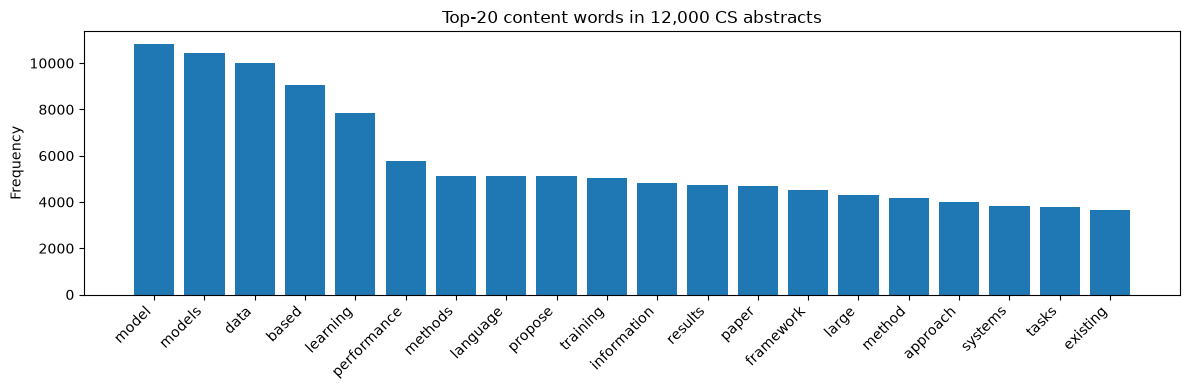

In [11]:
# Top-20 content words over the whole sample (stop-words removed), Week 1 frequency plot
word_counts = Counter()
for text in df["abstract"]:
    for word in simple_words(text):
        if word not in STOP_WORDS and len(word) > 2:
            word_counts[word] += 1

top20 = word_counts.most_common(20)
plt.figure(figsize=(12, 4))
plt.bar([w for w, c in top20], [c for w, c in top20])
plt.xticks(rotation=45, ha="right")
plt.title("Top-20 content words in 12,000 CS abstracts")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

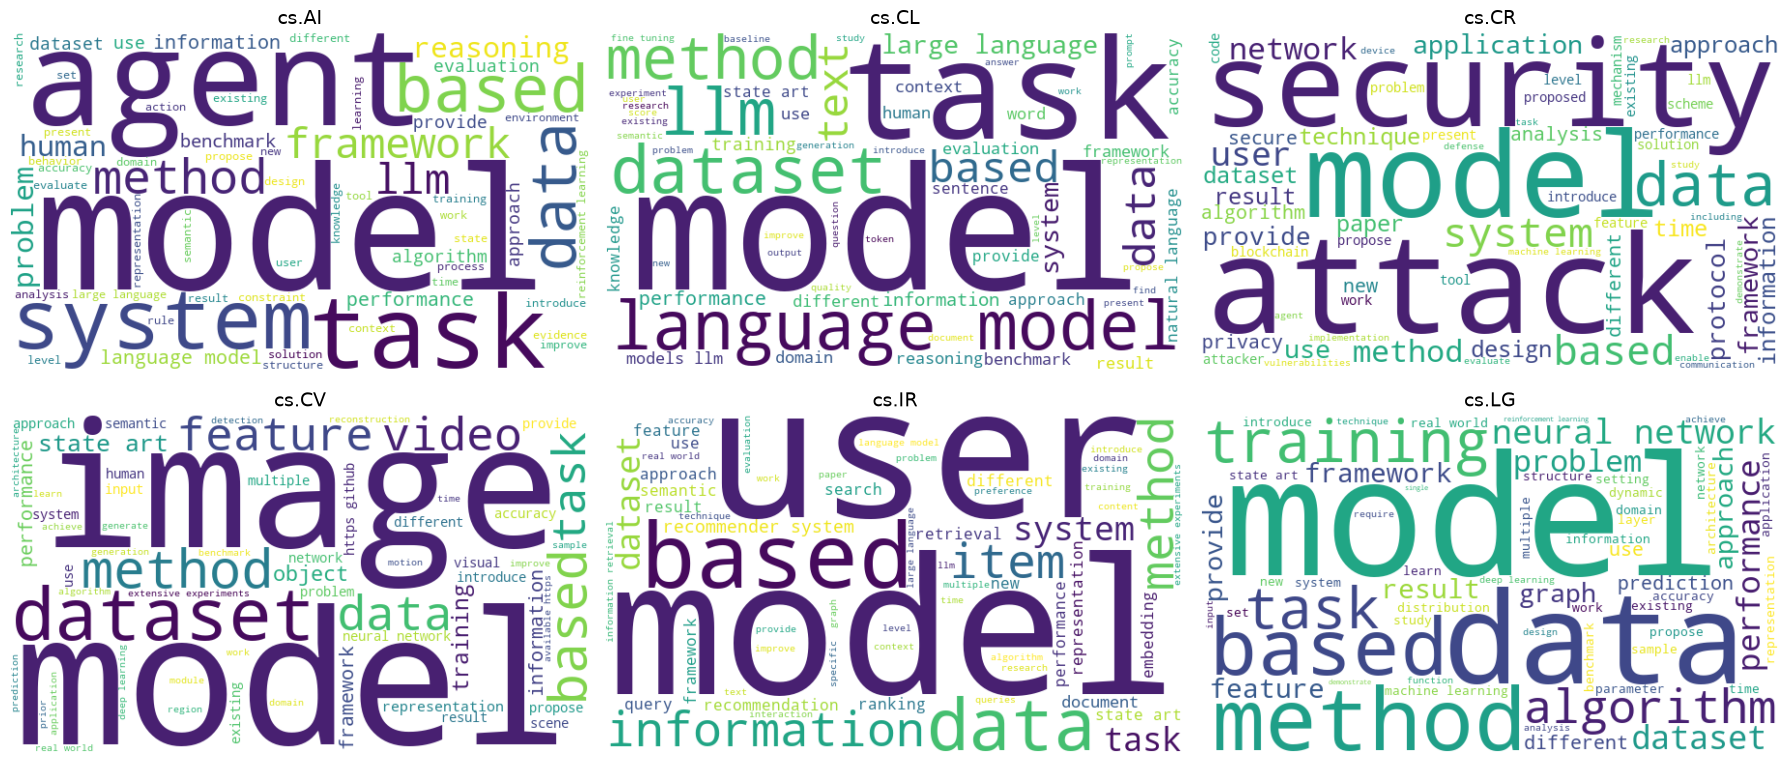

In [12]:
# One word cloud per research domain (Week 1, section 4)
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, category in zip(axes.ravel(), CATEGORIES):
    words = []
    for text in df.loc[df["primary_category"] == category, "abstract"]:
        words.extend(w for w in simple_words(text) if w not in STOP_WORDS and len(w) > 2)
    cloud = WordCloud(width=600, height=350, background_color="white", max_words=60,
                      random_state=SEED).generate(" ".join(words))
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(category, fontsize=14)
    ax.axis("off")
plt.tight_layout()
plt.show()

> **Justification (owner, 2-4 lines in your own words):** _why this technique, which week it comes from, what it adds to the system._

## Preprocessing pipeline

`extraction.preprocess(text)` (Week 2): clean the text (LaTeX maths, LaTeX commands, URLs, extra spaces), tokenise with spaCy, lowercase, drop stop-words, punctuation and numbers, then lemmatise. The LaTeX rules were added to the Week 2 `clean_text` because about 7% of abstracts contain `$...$` maths.

> **Justification (owner, 2-4 lines in your own words):** _why this technique, which week it comes from, what it adds to the system._

In [13]:
# One abstract that contains LaTeX, before and after each step
has_early_latex = df["abstract"].str.find("$").between(0, 250)   # a "$" in the first 250 characters
example = df[has_early_latex].iloc[0]["abstract"]
print("RAW:\n", example[:400], "\n")
print("CLEANED:\n", ex.clean_text(example)[:400], "\n")
print("TOKENS (no lemmatisation):\n", ex.preprocess(example, lemmatise=False)[:30], "\n")
print("TOKENS (lemmatised):\n", ex.preprocess(example)[:30])

RAW:
 Prompt-learning has become a new paradigm in modern natural language processing, which directly adapts pre-trained language models (PLMs) to $cloze$-style prediction, autoregressive modeling, or sequence to sequence generation, resulting in promising performances on various tasks. However, no standard implementation framework of prompt-learning is proposed yet, and most existing prompt-learning co 

CLEANED:
 Prompt-learning has become a new paradigm in modern natural language processing, which directly adapts pre-trained language models (PLMs) to -style prediction, autoregressive modeling, or sequence to sequence generation, resulting in promising performances on various tasks. However, no standard implementation framework of prompt-learning is proposed yet, and most existing prompt-learning codebases 

TOKENS (no lemmatisation):
 ['prompt', 'learning', 'new', 'paradigm', 'modern', 'natural', 'language', 'processing', 'directly', 'adapts', 'pre', 'trained', 'language', 'models',

In [14]:
# Stemming (NLTK Porter) vs lemmatisation (spaCy) on words that are common in the corpus (Week 2, section 4)
stemmer = PorterStemmer()
nlp = ex.get_nlp()
test_words = ["networks", "learning", "studies", "proposed", "better", "models",
              "trained", "datasets", "analyses", "efficiency", "generalization", "queries"]

comparison = []
for word in test_words:
    comparison.append({"word": word, "stem": stemmer.stem(word), "lemma": nlp(word)[0].lemma_})
pd.DataFrame(comparison)

,word,stem,lemma
0,networks,network,network
1,learning,learn,learn
2,studies,studi,study
3,proposed,propos,propose
4,better,better,well
5,models,model,model
6,trained,train,train
7,datasets,dataset,dataset
8,analyses,analys,analysis
9,efficiency,effici,efficiency


In [15]:
# How much each step shrinks the vocabulary, on 1,000 training abstracts (takes about 30 s)
sample_texts = train_df.sample(n=1000, random_state=SEED)["abstract"].tolist()

raw_vocab, no_stop_vocab, stem_vocab, lemma_vocab = set(), set(), set(), set()
for text in sample_texts:
    words = simple_words(text)
    raw_vocab.update(words)
    surface = ex.preprocess(text, lemmatise=False)
    no_stop_vocab.update(surface)
    stem_vocab.update(stemmer.stem(w) for w in surface)
    lemma_vocab.update(ex.preprocess(text))

vocab_reduction = pd.DataFrame({
    "step": ["raw lowercase words", "cleaned, no stop-words/punct/numbers", "+ Porter stemming", "+ spaCy lemmatisation"],
    "vocab_size": [len(raw_vocab), len(no_stop_vocab), len(stem_vocab), len(lemma_vocab)],
})
results["vocab_reduction_1000_abstracts"] = dict(zip(vocab_reduction["step"], vocab_reduction["vocab_size"]))
vocab_reduction

,step,vocab_size
0,raw lowercase words,11417
1,"cleaned, no stop-words/punct/numbers",10818
2,+ Porter stemming,6483
3,+ spaCy lemmatisation,8466


## POS-based key phrases

Week 3 POS tagging. `pos_key_phrases` keeps token runs that match the pattern `ADJ* NOUN+` (for example "masked autoencoder", "bipartite matching"); spaCy's `noun_chunks` is used as a second, parser-based way to get noun phrases. Both are run on a fixed sample of 600 test papers (about 100 per domain).

> **Justification (owner, 2-4 lines in your own words):** _why this technique, which week it comes from, what it adds to the system._

In [16]:
analysis_df = test_df.sample(n=600, random_state=SEED).reset_index(drop=True)
docs = list(nlp.pipe([ex.clean_text(t) for t in analysis_df["abstract"]]))
print(len(docs), "abstracts parsed")

600 abstracts parsed


In [17]:
# POS tags of the first sentence of one abstract, then the phrases each method finds
doc = docs[0]
first_sentence = list(doc.sents)[0]
print(analysis_df.loc[0, "title"], "\n")
print(pd.DataFrame([(t.text, t.pos_, t.tag_) for t in first_sentence], columns=["token", "POS", "tag"]).T.to_string(header=False))
print("\nADJ* NOUN+ key phrases:", ex.pos_key_phrases(doc)[:12])
print("\nspaCy noun chunks:     ", ex.noun_chunks(doc)[:12])

The Right to be Forgotten in Federated Learning: An Efficient Realization with Rapid Retraining 

token   In  Machine  Learning      ,  the  emergence   of  the  right    to   be  forgotten  gave  birth   to    a  paradigm  named  machine  unlearning      ,  which  enables  data  holders    to  proactively  erase  their  data  from    a  trained  model      .
POS    ADP    PROPN     PROPN  PUNCT  DET       NOUN  ADP  DET   NOUN  PART  AUX       VERB  VERB   NOUN  ADP  DET      NOUN   VERB     NOUN        NOUN  PUNCT   PRON     VERB  NOUN     NOUN  PART          ADV   VERB   PRON  NOUN   ADP  DET     VERB   NOUN  PUNCT
tag     IN      NNP       NNP      ,   DT         NN   IN   DT     NN    TO   VB        VBN   VBD     NN   IN   DT        NN    VBN       NN          NN      ,    WDT      VBZ   NNS      NNS    TO           RB     VB   PRP$   NNS    IN   DT      VBN     NN      .

ADJ* NOUN+ key phrases: ['machine learning', 'machine unlearning', 'data holders', 'techniques focus', 'centr

In [18]:
# Most frequent key phrases per research domain
phrase_rows = {}
phrases_per_paper = []
chunks_per_paper = []
category_counters = {}
for category in CATEGORIES:
    counter = Counter()
    for doc, cat in zip(docs, analysis_df["primary_category"]):
        if cat == category:
            counter.update(set(ex.pos_key_phrases(doc)))      # set(): count each phrase once per paper
    category_counters[category] = counter

# A phrase in the top-25 of 3 or more domains ("extensive experiments", "experimental results")
# says nothing about the domain, so it is treated as generic and hidden from the table.
top_lists = Counter()
for counter in category_counters.values():
    top_lists.update(p for p, c in counter.most_common(25))
generic_phrases = {p for p, n in top_lists.items() if n >= 3}
print("Generic phrases removed:", sorted(generic_phrases))

for category, counter in category_counters.items():
    phrase_rows[category] = [p for p, c in counter.most_common(40) if p not in generic_phrases][:5]
for doc in docs:
    phrases_per_paper.append(len(ex.pos_key_phrases(doc)))
    chunks_per_paper.append(len(ex.noun_chunks(doc)))

results["mean_key_phrases_per_paper"] = round(float(np.mean(phrases_per_paper)), 1)
results["mean_noun_chunks_per_paper"] = round(float(np.mean(chunks_per_paper)), 1)
print("Mean key phrases per paper:", results["mean_key_phrases_per_paper"],
      "| mean noun chunks per paper:", results["mean_noun_chunks_per_paper"])
pd.DataFrame(phrase_rows)

Generic phrases removed: ['art performance', 'experimental results', 'extensive experiments', 'large language model', 'large language models', 'machine learning', 'real-world', 'reinforcement learning', 'wide range']
Mean key phrases per paper: 25.3 | mean noun chunks per paper: 27.3


,cs.AI,cs.CL,cs.CR,cs.CV,cs.IR,cs.LG
0,artificial intelligence,language models,adversarial attacks,deep learning,recommender systems,neural networks
1,multi-agent systems,natural language processing,prior work,art methods,collaborative filtering,source code
2,observable markov decision processes,better results,sensitive information,computer vision,information retrieval,competitive performance
3,optimization objective,further research,% accuracy,previous methods,real-world datasets,deep learning
4,domain knowledge,dialogue systems,recent years,benchmark datasets,large-scale,deep neural networks


## NER and regex extraction

Two non-LLM ways to find the paper's named methods and datasets:
- **spaCy NER** (Week 3): the pretrained `en_core_web_sm` entity recogniser. It was trained on news text, so it has no METHOD or DATASET label and tags most model names as ORG or PRODUCT.
- **Regex rules** (Week 3, rule-based IE): mixed-case acronyms such as `BERT`, `ImageNet-1k`, `GPT-4o` (a stop-list removes generic ones like `AI`, `LLMs`), acronym definitions "Long Form (LF)", names followed by "dataset/benchmark/corpus", plus years and percentages.

> **Justification (owner, 2-4 lines in your own words):** _why this technique, which week it comes from, what it adds to the system._

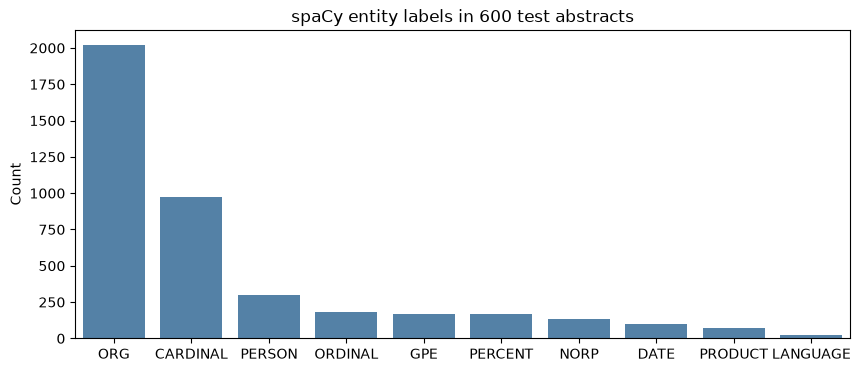

Most common ORG/PRODUCT entities: [('LLM', 55), ('NLP', 29), ('ML', 24), ('RL', 20), ('Transformer', 18), ('LoRA', 17), ('IoT', 15), ('BERT', 14), ('API', 13), ('CNN', 13), ('Large Language Models', 12), ('IP', 12), ('IR', 11), ('RowHammer', 10), ('PI', 10)]


In [19]:
# Which entity labels does spaCy assign in research abstracts?
label_counts = Counter()
org_product = Counter()
for doc in docs:
    for ent in doc.ents:
        label_counts[ent.label_] += 1
        if ent.label_ in ("ORG", "PRODUCT"):
            org_product[ent.text] += 1

results["spacy_entity_labels_600_papers"] = dict(label_counts.most_common(10))
labels, counts = zip(*label_counts.most_common(10))
plt.figure(figsize=(10, 4))
sns.barplot(x=list(labels), y=list(counts), color="steelblue")
plt.title("spaCy entity labels in 600 test abstracts")
plt.ylabel("Count")
plt.show()
print("Most common ORG/PRODUCT entities:", org_product.most_common(15))

In [20]:
# Regex extraction over the same 600 papers
acronym_counts = Counter()
n_definitions = 0
n_dataset_mentions = 0
papers_with_year = 0
for text in analysis_df["abstract"]:
    rules = ex.regex_extract(text)
    acronym_counts.update(rules["acronyms"])
    n_definitions += len(rules["definitions"])
    n_dataset_mentions += len(rules["datasets"])
    if rules["years"]:
        papers_with_year += 1

results["regex_600_papers"] = {"acronym_definitions": n_definitions,
                               "dataset_mentions": n_dataset_mentions,
                               "papers_with_a_year": papers_with_year}
print(results["regex_600_papers"])
print("Most common specific acronyms/names:", acronym_counts.most_common(20))

{'acronym_definitions': 299, 'dataset_mentions': 56, 'papers_with_a_year': 31}
Most common specific acronyms/names: [('RAG', 10), ('ImageNet', 9), ('LSTM', 7), ('BERT', 7), ('RS', 6), ('ASR', 6), ('FL', 5), ('GRPO', 5), ('LoRA', 5), ('CoT', 5), ('KG', 5), ('CIFAR-10', 5), ('ChatGPT', 5), ('CT', 4), ('SFT', 4), ('MAE', 4), ('GPT-4o', 4), ('RAM', 4), ('GLUE', 4), ('OpenClaw', 4)]


In [21]:
# Everything the basic extractors return for one paper (this is what NB06 shows in the demo)
i = 1
print(analysis_df.loc[i, "title"], "\n")
for key, value in ex.extract(analysis_df.loc[i, "abstract"]).items():
    print(f"{key:12s} {value[:8]}")

Sequential Recommendation via Stochastic Self-Attention 

key_phrases  ['sequential recommendation models', 'previous behaviors', 'next item', 'dot-product self-attention', 'superior capabilities', 'sequential methods', 'real-world', 'sequential behaviors']
noun_chunks  ['sequential recommendation models', "user's previous behaviors", 'next item', 'transformer-based approaches', 'dot-product self-attention', 'superior capabilities', 'existing sequential methods', "users' real-world sequential behaviors"]
entities     [('Sequential', 'GPE'), ('BPR', 'ORG'), ('STOchastic Self-Attention~(STOSA', 'ORG'), ('Wasserstein Self-Attention', 'PERSON'), ('Wasserstein', 'PERSON')]
acronyms     ['BPR', 'STOchastic', 'STOSA']
definitions  []
datasets     []
years        []
percentages  []


In [22]:
# Agreement between the two extractors: how many regex names does spaCy also tag as an entity?
both, regex_only = 0, 0
for doc, text in zip(docs, analysis_df["abstract"]):
    entity_texts = {ent.text for ent in doc.ents}
    for name in ex.regex_artefacts(text):
        if name in entity_texts:
            both += 1
        else:
            regex_only += 1
results["regex_names_also_found_by_spacy"] = round(both / max(both + regex_only, 1), 3)
print(f"{both} of {both + regex_only} regex names are also spaCy entities "
      f"({results['regex_names_also_found_by_spacy']:.0%})")

763 of 1407 regex names are also spaCy entities (54%)


## Few-shot LLM extraction

Advanced technique (Week 9 few-shot prompting): an instruction, three worked examples and the new abstract, asking for JSON with `methods`, `datasets` and `tasks`. The three example abstracts were written for this prompt (they are not real papers) so they cannot leak test data. The call goes through the team's shared `llm.generate` (temperature 0, cached in `artifacts/llm_cache.jsonl`).

> **Justification (owner, 2-4 lines in your own words):** _why this technique, which week it comes from, what it adds to the system._

In [23]:
import llm
print("LLM backend:", llm.describe())
print(ex.build_few_shot_prompt(analysis_df.loc[1, "abstract"])[-900:])

LLM backend: {'backend': 'hf', 'model': 'Qwen/Qwen2.5-1.5B-Instruct'}
tive items, which misleads the optimization. We propose a novel STOchastic Self-Attention~(STOSA) to overcome these issues. STOSA, in particular, embeds each item as a stochastic Gaussian distribution, the covariance of which encodes the uncertainty. We devise a novel Wasserstein Self-Attention module to characterize item-item position-wise relationships in sequences, which effectively incorporates uncertainty into model training. Wasserstein attentions also enlighten the collaborative transitivity learning as it satisfies triangle inequality. Moreover, we introduce a novel regularization term to the ranking loss, which assures the dissimilarity between positive and the negative items. Extensive experiments on five real-world benchmark datasets demonstrate the superiority of the proposed model over state-of-the-art baselines, especially on cold start items. The code is available in
JSON:


In [24]:
print(analysis_df.loc[1, "title"])
ex.llm_extract(analysis_df.loc[1, "abstract"])

Sequential Recommendation via Stochastic Self-Attention


{'methods': ['Transformer-based approaches',
  'dot-product self-attention',
  'BPR loss',
  'Wasserstein Self-Attention',
  'regularization term'],
 'datasets': ['five real-world benchmark datasets'],
 'tasks': ['sequential recommendation']}

## Evaluation on hand-labelled abstracts

20 test papers (fixed seed) are labelled by hand in `artifacts/02_gold_labels.json`. The first run of the next cell creates that file with empty lists.

**How to label:** open the JSON, read each abstract, fill `methods` (named models/algorithms), `datasets` (named datasets/benchmarks) and `tasks`, copying names exactly as written in the abstract, then set `"labelled": true`. Re-run this section afterwards.

Scoring: micro precision / recall / F1 over the combined `methods + datasets` names, with a relaxed match (equal after lowercasing and removing punctuation, or one name contains the other, e.g. "BERT" vs "BERT-base").

> **Justification (owner, 2-4 lines in your own words):** _why this technique, which week it comes from, what it adds to the system._

In [25]:
GOLD_PATH = ARTIFACTS_DIR / "02_gold_labels.json"

if not GOLD_PATH.exists():
    to_label = test_df.sample(n=20, random_state=SEED + 1)
    template = []
    for _, row in to_label.iterrows():
        template.append({"id": row["id"], "title": row["title"], "abstract": row["abstract"],
                         "methods": [], "datasets": [], "tasks": [], "labelled": False})
    GOLD_PATH.write_text(json.dumps(template, indent=2, ensure_ascii=False), encoding="utf-8")
    print("Created", GOLD_PATH, "- label it, then re-run this section.")

gold = json.loads(GOLD_PATH.read_text(encoding="utf-8"))
labelled = [g for g in gold if g["labelled"]]
print(f"{len(labelled)} of {len(gold)} abstracts labelled")

0 of 20 abstracts labelled


In [26]:
def score(extractor_name, predict):
    """Micro P/R/F1 of one extractor over all labelled abstracts."""
    tp_total, pred_total, gold_total = 0, 0, 0
    for item in labelled:
        gold_names = item["methods"] + item["datasets"]
        tp, n_pred, n_gold = ex.match_counts(predict(item), gold_names)
        tp_total += tp
        pred_total += n_pred
        gold_total += n_gold
    p, r, f1 = ex.precision_recall_f1(tp_total, pred_total, gold_total)
    return {"extractor": extractor_name, "precision": p, "recall": r, "f1": f1,
            "predicted": pred_total, "gold": gold_total}


if labelled:
    llm_outputs = {item["id"]: ex.llm_extract(item["abstract"]) for item in labelled}   # 20 LLM calls, cached
    extraction_scores = pd.DataFrame([
        score("Regex rules", lambda item: ex.regex_artefacts(item["abstract"])),
        score("spaCy NER (ORG/PRODUCT)", lambda item: ex.spacy_artefacts(item["abstract"])),
        score("Few-shot LLM", lambda item: llm_outputs[item["id"]]["methods"] + llm_outputs[item["id"]]["datasets"]),
    ])
    results["extraction_scores"] = extraction_scores.to_dict(orient="records")
    results["n_labelled_abstracts"] = len(labelled)
    display(extraction_scores)
else:
    results["extraction_scores"] = "not run: gold labels not filled in yet"
    print(results["extraction_scores"])

not run: gold labels not filled in yet


In [27]:
# Error analysis: one labelled paper, gold vs each extractor
if labelled:
    item = labelled[0]
    print(item["title"], "\n")
    print("GOLD :", item["methods"] + item["datasets"])
    print("REGEX:", ex.regex_artefacts(item["abstract"]))
    print("SPACY:", ex.spacy_artefacts(item["abstract"]))
    print("LLM  :", llm_outputs[item["id"]])

## Findings and limitations

> **Owner, 2-4 lines each, from the numbers above:**
> - Which extractor had the best precision / recall, and why (rules are precise but miss names without capitals; spaCy NER has no METHOD/DATASET label).
> - What the vocabulary-reduction table shows about lemmatisation vs stemming.
> - Limitations: only 20 hand-labelled abstracts, one annotator, relaxed matching; spaCy POS errors (e.g. verbs tagged as nouns create phrases like "depth estimation enhances").

In [28]:
path = save_results("02", results)
print("Saved", path)
results

Saved /Users/zeronezsmacbook/Desktop/edi/COMP8460 Artificial Intelligence for Natural Language Processing Applications/assignment3/GroupID_Assignment3/codes/artifacts/02_results.json


{'corpus_stats': [{'category': 'cs.AI',
   'papers': 2000,
   'mean_words': 178.8,
   'vocab_size': 15258,
   'type_token_ratio': 0.0427},
  {'category': 'cs.CL',
   'papers': 2000,
   'mean_words': 168.6,
   'vocab_size': 13824,
   'type_token_ratio': 0.041},
  {'category': 'cs.CR',
   'papers': 2000,
   'mean_words': 181.8,
   'vocab_size': 15245,
   'type_token_ratio': 0.0419},
  {'category': 'cs.CV',
   'papers': 2000,
   'mean_words': 187.2,
   'vocab_size': 14714,
   'type_token_ratio': 0.0393},
  {'category': 'cs.IR',
   'papers': 2000,
   'mean_words': 184.8,
   'vocab_size': 13308,
   'type_token_ratio': 0.036},
  {'category': 'cs.LG',
   'papers': 2000,
   'mean_words': 182.6,
   'vocab_size': 14251,
   'type_token_ratio': 0.039}],
 'vocab_reduction_1000_abstracts': {'raw lowercase words': 11417,
  'cleaned, no stop-words/punct/numbers': 10818,
  '+ Porter stemming': 6483,
  '+ spaCy lemmatisation': 8466},
 'mean_key_phrases_per_paper': 25.3,
 'mean_noun_chunks_per_paper': 27